In [ ]:
%pip install numpy scipy matplotlib pandas -i https://pypi.tuna.tsinghua.edu.cn/simple

In [3]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080129
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080129
[机器指纹] eff28411a62a643f
[RUN_ID] 20244080129-eff28411a62a643f


NumPy 数组、数据类型与索引。
1.NumPy 数组通常要求元素具有统一的数据类型，因此可以高效地进行批量数值运算；Python 列表可以混合不同类型的元素，但进行数值运算时通常需要逐个处理。NumPy 数组还支持多维形状和向量化运算。
2.改变形状时，元素总数必须保持不变。例如，3 × 4 = 12、2 × 3 × 2 = 12，都与原数组的 12 个元素相符。
3.这里按常见中文习惯将“第 2 行”“第 1 至第 3 列”理解为从 1 开始计数。NumPy 索引从 0 开始，所以对应 arr_3x4[1, :] 和 arr_3x4[:, 0:3]。布尔索引取出的结果是一维数组。
4.使用 |、& 组合条件时，每个条件都要加括号。
5.* 和 np.multiply() 对应位置的元素相乘；@ 和 np.matmul() 执行矩阵乘法，即行与列相乘后求和。对于这里的数组，逐元素乘法结果是 [[5, 12], [21, 32]]，矩阵乘法结果是 [[19, 22], [43, 50]]。

In [1]:
import numpy as np

int_arr = np.array([1, 2, 3])
float_arr = np.array([1.0, 2.5, 3.8])
bool_arr = np.array([True, False, True])

for name, arr in [
    ("整数数组", int_arr),
    ("浮点数数组", float_arr),
    ("布尔数组", bool_arr),
]:
    print(f"{name}: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

arr = np.arange(12)
arr_3x4 = arr.reshape(3, 4)
arr_2x3x2 = arr.reshape(2, 3, 2)

print("一维数组：")
print(arr)

print("(3, 4) 数组：")
print(arr_3x4)

print("(2, 3, 2) 数组：")
print(arr_2x3x2)

arr_3x4 = np.arange(12).reshape(3, 4)
print("连续调用两个方法求（3，4）数组：")
print(arr_3x4)

second_row = arr_3x4[1, :]
cols_1_to_3 = arr_3x4[:, 0:3]
greater_than_6 = arr_3x4[arr_3x4 > 6]

print("第 2 行：", second_row, "shape =", second_row.shape)
print("第 1 至第 3 列：\n", cols_1_to_3, "shape =", cols_1_to_3.shape)
print("大于 6 的元素：", greater_than_6, "shape =", greater_than_6.shape)

arr = np.arange(10)

less_2_or_greater_7 = arr[(arr < 2) | (arr > 7)]
greater_3_and_less_7 = arr[(arr > 3) & (arr < 7)]

print("（用or）小于 2 或大于 7：", less_2_or_greater_7)
print("（用and）大于 3 且小于 7：", greater_3_and_less_7)
condition_or = np.logical_or(arr < 2, arr > 7)
result_or = arr[condition_or]

condition_and = np.logical_and(arr > 3, arr < 7)
result_and = arr[condition_and]

print("（用logical-or）小于 2 或大于 7：", result_or)
print("（用logical-and）大于 3 且小于 7：", result_and)


A = np.array([[1, 2],
              [3, 4]])

B = np.array([[5, 6],
              [7, 8]])

print("A * B（逐元素乘法）：")
print(A * B)

print("np.multiply(A, B)（逐元素乘法）：")
print(np.multiply(A, B))

print("A @ B（矩阵乘法）：")
print(A @ B)

print("np.matmul(A, B)（矩阵乘法）：")
print(np.matmul(A, B))

整数数组: dtype=int64, shape=(3,), ndim=1
浮点数数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1
一维数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]
(3, 4) 数组：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 3, 2) 数组：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
连续调用两个方法求（3，4）数组：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
第 2 行： [4 5 6 7] shape = (4,)
第 1 至第 3 列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape = (3, 3)
大于 6 的元素： [ 7  8  9 10 11] shape = (5,)
（用or）小于 2 或大于 7： [0 1 8 9]
（用and）大于 3 且小于 7： [4 5 6]
（用logical-or）小于 2 或大于 7： [0 1 8 9]
（用logical-and）大于 3 且小于 7： [4 5 6]
A * B（逐元素乘法）：
[[ 5 12]
 [21 32]]
np.multiply(A, B)（逐元素乘法）：
[[ 5 12]
 [21 32]]
A @ B（矩阵乘法）：
[[19 22]
 [43 50]]
np.matmul(A, B)（矩阵乘法）：
[[19 22]
 [43 50]]


随机抽样、统计与缺失值。
1.np.clip 会将低于 0 的值设为 0、高于 100 的值设为 100
2.两种方式都通过 replace=False 指定不放回抽样；加权抽样通过 p 传入概率，概率之和必须为 1。
3.permutation 返回新数组，原数组保持不变；shuffle 则直接修改传入的数组。
4.普通统计函数如 np.mean 遇到 np.nan 通常会返回 nan；np.nanmean 会忽略缺失值后再计算。
5.df_exp04 是内存中的 pandas 表格变量，没有写入磁盘。实验 4 在同一个 Notebook 内核中可以直接使用它；如果重启内核，需要重新运行前面的代码单元来创建这个变量。

In [7]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数：", scores.size)
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())  # 默认计算总体标准差
print("极差：", scores.max() - scores.min())

numbers = np.arange(1, 11)

# 均匀抽样：每个整数被抽中的概率相同
uniform_sample = rng.choice(numbers, size=5, replace=False)

# 加权抽样：整数越大，权重越高；权重按整数值成比例设置
probabilities = numbers / numbers.sum()
weighted_sample = rng.choice(
    numbers,
    size=5,
    replace=False,
    p=probabilities
)

print("均匀抽样：", uniform_sample)
print("按整数大小加权抽样：", weighted_sample)

# permutation 返回一个新数组，不改变原数组
original = np.arange(1, 11)
print("排列前原数组：", original)

permuted = rng.permutation(original)
print("随机排列结果：", permuted)
print("排列后原数组：", original)

# shuffle 原地打乱传入的数组
to_shuffle = np.arange(1, 11)
print("\n原地打乱前：", to_shuffle)

rng.shuffle(to_shuffle)
print("原地打乱后：", to_shuffle)

scores_with_nan = scores.copy()

# 第 10、20、30 个值（Python 索引分别为 9、19、29）设为缺失
scores_with_nan[[9, 19, 29]] = np.nan

print("普通均值：", np.mean(scores_with_nan))
print("忽略缺失值后的均值：", np.nanmean(scores_with_nan))
print("缺失值个数：", np.isnan(scores_with_nan).sum())

df_exp04 = pd.DataFrame({
    "序号": np.arange(1, len(scores_with_nan) + 1),
    "成绩": scores_with_nan
})

print(df_exp04.head())
print("表格行数：", len(df_exp04))
print("缺失成绩数：", df_exp04["成绩"].isna().sum())

样本数： 1000
最小值： 33.51587174785217
最大值： 100.0
均值： 69.70929595324685
标准差： 9.881580939490172
极差： 66.48412825214783
均匀抽样： [7 2 9 5 4]
按整数大小加权抽样： [3 9 2 6 5]
排列前原数组： [ 1  2  3  4  5  6  7  8  9 10]
随机排列结果： [ 2 10  3  5  1  9  7  8  4  6]
排列后原数组： [ 1  2  3  4  5  6  7  8  9 10]

原地打乱前： [ 1  2  3  4  5  6  7  8  9 10]
原地打乱后： [ 1  2 10  3  6  8  9  4  5  7]
普通均值： nan
忽略缺失值后的均值： 69.71315691233939
缺失值个数： 3
   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
表格行数： 1000
缺失成绩数： 3


SciPy 数值计算与 Matplotlib 可视化

解 [x, y]： [2. 3.]
代入左侧： [9. 8.]
右侧： [9 8]
是否成立： True
正根求根成功： True
正根： 1.4142135623730947
函数值： -8.881784197001252e-16
负根求根成功： True
负根： -1.4142135623730947
函数值： -8.881784197001252e-16
求解成功： True
极小点： -0.5000000064345924
函数最小值： 1.75
解析极小点： -0.5
解析最小值： 1.75
t 统计量： -8.316637727945347
p 值： 1.441895340492072e-14
在 0.05 显著性水平下，拒绝两组均值相等的原假设。


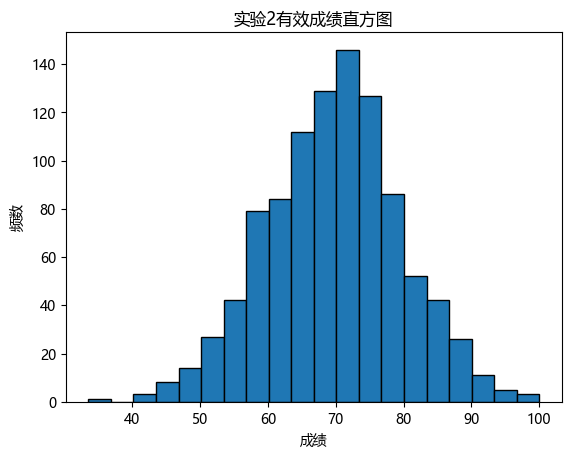

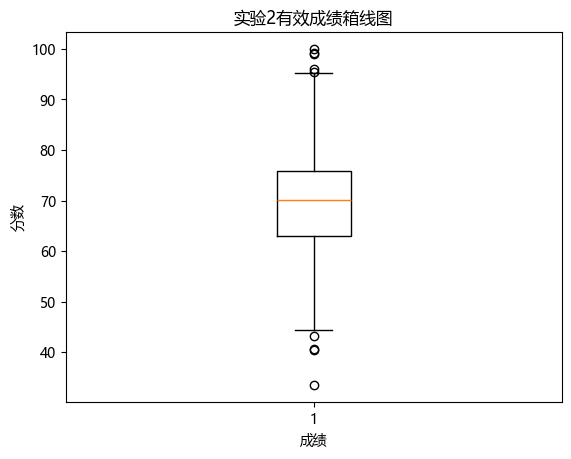

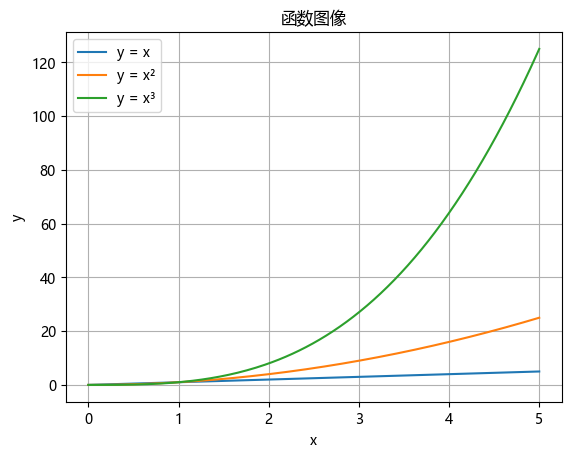

In [10]:
import numpy as np
from scipy.linalg import solve
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])

solution = solve(A, b)
print("解 [x, y]：", solution)

# 代入原方程验证
print("代入左侧：", A @ solution)
print("右侧：", b)
print("是否成立：", np.allclose(A @ solution, b))

from scipy.optimize import root

def equation(x):
    return x**2 - 2

positive_result = root(equation, x0=[1.0])
negative_result = root(equation, x0=[-1.0])

for label, result in [("正根", positive_result), ("负根", negative_result)]:
    root_value = result.x[0]
    print(f"{label}求根成功：", result.success)
    print(f"{label}：", root_value)
    print("函数值：", equation(root_value))

from scipy.optimize import minimize

def f(x):
    return x[0]**2 + x[0] + 2

result = minimize(f, x0=[0.0])

print("求解成功：", result.success)
print("极小点：", result.x[0])
print("函数最小值：", result.fun)

# 解析结果：配方后，f(x) = (x + 1/2)^2 + 7/4
print("解析极小点：", -0.5)
print("解析最小值：", 1.75)

from scipy.stats import ttest_ind

rng = np.random.default_rng(42)
sample_1 = rng.normal(loc=0, scale=1, size=100)
sample_2 = rng.normal(loc=1, scale=1, size=100)

test_result = ttest_ind(sample_1, sample_2)

print("t 统计量：", test_result.statistic)
print("p 值：", test_result.pvalue)

if test_result.pvalue < 0.05:
    print("在 0.05 显著性水平下，拒绝两组均值相等的原假设。")
else:
    print("在 0.05 显著性水平下，没有足够证据拒绝两组均值相等的原假设。")

import matplotlib.pyplot as plt

# 从实验 2 的表格中取出有效成绩，排除缺失值
valid_scores = df_exp04["成绩"].dropna()

# 成绩直方图
plt.figure()
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("实验2有效成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.show()

# 成绩箱线图
plt.figure()
plt.boxplot(valid_scores)
plt.title("实验2有效成绩箱线图")
plt.xlabel("成绩")
plt.ylabel("分数")
plt.show()

# y=x、y=x²、y=x³ 的折线图
x = np.linspace(0, 5, 200)

plt.figure()
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x²")
plt.plot(x, x**3, label="y = x³")
plt.title("函数图像")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

pandas Series、DataFrame 与内存中的CSV 读写。
协方差约为 62.57，是正数，说明在这组学生数据中，数学成绩较高的学生往往英语成绩也较高，二者整体呈同向变化。
相关系数约为 0.654，介于 -1 和 1 之间，且为正，表示两科成绩有中等程度的正线性相关。相关系数越接近 1，正相关越强；越接近 0，线性相关越弱。这里只是这几位学生成绩之间的相关性，不能据此推断数学成绩提高会导致英语成绩提高。

In [ ]:
import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "B", "A"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")

subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前 3 行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

# loc 根据行索引标签读取
print("用 loc 读取 Carol：")
print(df.loc["Carol"])

# iloc 根据行的位置读取；Carol 是第 3 行，所以位置索引是 2
print("\n用 iloc 读取 Carol：")
print(df.iloc[2])

print("\n平均分不低于 80 的学生：")
print(df.loc[df["Average"] >= 80])

print("各科平均分（mean(axis=0)，按列计算）：")
print(df[subjects].mean(axis=0))

print("\n每位学生的三科平均分（mean(axis=1)，按行计算）：")
print(df[subjects].mean(axis=1))

# 对每一行应用 max，得到每位学生的三科最高分
df["最高分"] = df[subjects].apply(max, axis=1)

# 对每一科分别计算最小值、均值和最大值
print("各科统计：")
print(df[subjects].agg(["min", "mean", "max"]))

# Python 成绩排名：分数越高，名次数字越小
df["Python排名"] = df["Python"].rank(
    ascending=False,
    method="min"
).astype(int)

print("\n包含最高分和 Python 排名的表格：")
print(df)

grouped = df.groupby("Group")

print("各组人数：")
print(grouped.size())

print("\n各组三科平均分：")
print(grouped[subjects].mean())

# 为每位学生添加其所在组的 Python 平均分
df["组内Python平均分"] = grouped["Python"].transform("mean")

print("\n包含组内 Python 平均分的表格：")
print(df[["Group", "Python", "组内Python平均分"]])

qualified_groups = df.groupby("Group").filter(
    lambda group: group["Python"].mean() >= 80
)

print("保留的组及学生：")
print(qualified_groups[["Group", "Python"]])

print("三科成绩的协方差矩阵：")
print(df[subjects].cov())

print("\n三科成绩的相关系数矩阵：")
print(df[subjects].corr())

math_english_cov = df["Math"].cov(df["English"])
math_english_corr = df["Math"].corr(df["English"])

print("数学与英语的协方差：", math_english_cov)
print("数学与英语的相关系数：", math_english_corr)

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000
用 loc 读取 Carol：
Group              B
Math